In [44]:
import pandas as pd

df_deliveries = pd.read_csv("./maplefreight_delivery_delay_dataset.csv")

df_deliveries

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6030,SHP-101294,London ON,Quebec City QC,QuebecExpress,Standard,Refrigerated,Silver,12,496.9,1150.6,...,70.0,8.3,7.4,Snow,34.5,0.180,0,178.52,8.01,0
6031,SHP-104024,Mississauga ON,Montreal QC,MapleFreight Fleet,Express,Fragile,Bronze,3,1095.3,894.7,...,-19.0,2.4,7.5,Clear,19.5,0.216,1,238.47,17.42,0
6032,SHP-105201,Montreal QC,Toronto ON,MapleFreight Fleet,Standard,Bulk,Gold,2,865.9,1071.0,...,-1.0,19.0,3.2,Clear,61.0,0.470,1,63.29,12.51,0
6033,SHP-103776,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,General Freight,Silver,3,776.1,1199.8,...,-7.0,3.2,1.8,Clear,87.7,0.753,3,160.85,10.94,0


In [45]:
print(df_deliveries.shape)

display(df_deliveries.describe())

display(df_deliveries.info())


(6035, 23)


,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

None

In [46]:
columns = df_deliveries.columns
duplicate_count = df_deliveries[[col for col in columns if col != "shipment_id"
                                 ]][df_deliveries.duplicated() == True].count()
driver_experience_years_imputed = df_deliveries['driver_experience_years'].isna().sum()
weather_condition_imputed = df_deliveries['weather_condition'].isna().sum()
traffic_index_imputed = df_deliveries['traffic_index'].isna().sum()
fuel_cost_cad_imputed = df_deliveries['fuel_cost_cad'].isna().sum()

print("Dups:", duplicate_count)
print("Exp year Imputed:", driver_experience_years_imputed)
print("weather cond Imputed:", weather_condition_imputed)
print("traffic index Imputed:", traffic_index_imputed)
print("fuel cost cad Imputed:", fuel_cost_cad_imputed)


#inpecting cat column uniques
categorical_columns = df_deliveries.select_dtypes(include='str')
for cat in categorical_columns:
    vals = list(set(df_deliveries[cat]))
    # vals.sort()
    print(cat, vals)

#service level had some variables upprcased we will lower everything

df_deliveries['service_level'] = df_deliveries['service_level'].apply(str.lower)

print(list(set(df_deliveries['service_level'])))
# MOVING to after split for avoiding leakage
# df_test[df_test.index.isin(df_test['driver_experience_years'].isna().index)] = df_test['driver_experience_years'].median()
# df_deliveries['driver_experience_years']=df_deliveries['driver_experience_years'].fillna(df_deliveries['driver_experience_years'].median())

# # df_test[df_test.index.isin(df_test['weather_condition'].isna().index)] = df_test['weather_condition'].median()

# df_deliveries.dropna(subset=['weather_condition'],inplace=True)

# # df_test['weather_condition']=df_test['weather_condition'].fillna(df_test['weather_condition'].mode())

# # df_test[df_test.index.isin(df_test['traffic_index'].isna().index)] = df_test['traffic_index'].median()
# df_deliveries['traffic_index']=df_deliveries['traffic_index'].fillna(df_deliveries['traffic_index'].median())

# # df_test[df_test.index.isin(df_test['fuel_cost_cad'].isna().index)] = df_test['fuel_cost_cad'].median()
# df_deliveries['fuel_cost_cad']=df_deliveries['fuel_cost_cad'].fillna(df_deliveries['fuel_cost_cad'].median())

display(df_deliveries[df_deliveries.duplicated()])

display(df_deliveries.isna().sum())
display(df_deliveries.describe())


grouped = df_deliveries.groupby('delivered_late').count()
display(grouped)
not_late = grouped.loc[0]['shipment_id'] 
late = grouped.loc[1]['shipment_id']
total = not_late + late
print("not late, late, total", not_late,late, total)
#imbalanced dataset.
print(round(not_late/total,2) * 100, round(late/total,2)*100)

# grouped['late_%']= ;
# grouped['early_%']
print()

Dups: origin_city                  32
destination_city             32
carrier                      32
service_level                32
goods_type                   32
customer_priority_tier       32
shipment_month               32
distance_km                  32
weight_kg                    32
num_stops                    32
is_cross_border              32
scheduled_transit_hours      32
pickup_delay_minutes         32
driver_experience_years      32
vehicle_age_years            32
weather_condition            32
traffic_index                31
route_congestion_score       32
prior_late_deliveries_30d    32
fuel_cost_cad                32
actual_transit_hours         32
delivered_late               32
dtype: int64
Exp year Imputed: 210
weather cond Imputed: 150
traffic index Imputed: 121
fuel cost cad Imputed: 240
shipment_id ['SHP-100174', 'SHP-101068', 'SHP-100585', 'SHP-100976', 'SHP-101019', 'SHP-103378', 'SHP-101411', 'SHP-100955', 'SHP-101713', 'SHP-105546', 'SHP-100765', 'SHP-102

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
932,SHP-100457,Montreal QC,Toronto ON,PrairieLine,economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0
1443,SHP-103447,Toronto ON,Calgary AB,MapleFreight Fleet,standard,Bulk,Bronze,11,430.5,1018.4,...,5.0,4.9,9.3,Snow,24.2,0.468,3,106.86,10.49,0
2453,SHP-104541,London ON,Ottawa ON,NorthStar Carriers,standard,General Freight,Gold,11,608.8,637.0,...,-1.0,3.1,3.8,Clear,62.7,0.441,1,193.43,8.97,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
2920,SHP-101174,London ON,Edmonton AB,MapleFreight Fleet,standard,Refrigerated,Bronze,4,348.2,883.6,...,6.0,12.8,3.1,Clear,65.3,0.420,1,208.64,4.82,0
2956,SHP-103516,Toronto ON,Sudbury ON,PrairieLine,express,General Freight,Gold,10,215.3,603.7,...,9.0,6.1,5.0,Rain,79.3,0.600,1,211.34,7.80,1
3135,SHP-104402,Winnipeg MB,Sudbury ON,NorthStar Carriers,express,Refrigerated,Bronze,7,855.0,1098.4,...,-20.0,3.1,4.4,Storm,NaN,0.713,1,152.77,14.64,0
3184,SHP-101699,Toronto ON,Quebec City QC,QuebecExpress,express,General Freight,Bronze,9,523.3,775.9,...,30.0,10.6,5.5,Clear,75.7,0.636,1,239.41,9.88,0
3188,SHP-105617,Toronto ON,Quebec City QC,MapleFreight Fleet,standard,General Freight,Silver,12,465.2,928.4,...,4.0,3.8,3.8,Fog,69.2,0.612,1,197.80,9.61,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0


shipment_id                    0
origin_city                    0
destination_city               0
carrier                        0
service_level                  0
goods_type                     0
customer_priority_tier         0
shipment_month                 0
distance_km                    0
weight_kg                      0
num_stops                      0
is_cross_border                0
scheduled_transit_hours        0
pickup_delay_minutes           0
driver_experience_years      210
vehicle_age_years              0
weather_condition            150
traffic_index                121
route_congestion_score         0
prior_late_deliveries_30d      0
fuel_cost_cad                240
actual_transit_hours           0
delivered_late                 0
dtype: int64

,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
count,6035.000000,6035.000000,6.035000e+03,6035.000000,6035.000000,6035.000000,6035.000000,5825.000000,6035.000000,5914.000000,6035.000000,6035.000000,5795.000000,6035.000000,6035.000000
mean,6.543662,632.192742,6.928251e+03,2.477051,0.113007,10.500388,20.367688,6.497648,5.489461,55.146365,0.449778,1.305551,180.696552,11.186038,0.205800
std,3.448260,319.246133,8.375515e+04,1.707457,0.316628,4.758576,30.618617,4.659277,3.433676,17.592978,0.194500,1.158943,58.759928,5.957114,0.404318
min,1.000000,80.500000,3.000000e+01,0.000000,0.000000,1.000000,-20.000000,0.200000,0.100000,5.000000,0.000000,0.000000,30.000000,0.880000,0.000000
25%,4.000000,398.600000,4.960000e+02,1.000000,0.000000,7.060000,-6.000000,3.200000,3.000000,43.300000,0.318000,0.000000,140.595000,7.080000,0.000000
50%,7.000000,571.100000,8.271000e+02,2.000000,0.000000,9.850000,18.000000,5.400000,4.800000,55.000000,0.446000,1.000000,181.180000,10.050000,0.000000
75%,10.000000,804.850000,1.286300e+03,4.000000,0.000000,13.175000,41.000000,8.600000,7.200000,67.200000,0.583000,2.000000,220.950000,14.010000,0.000000
max,12.000000,2556.700000,2.999300e+06,5.000000,1.000000,37.400000,146.000000,35.000000,20.000000,100.000000,1.000000,8.000000,392.010000,55.380000,1.000000


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours
delivered_late,,,,,,,,,,,,,,,,,,,,,
0,4793,4793,4793,4793,4793,4793,4793,4793,4793,4793,...,4793,4793,4630,4793,4676,4694,4793,4793,4599,4793
1,1242,1242,1242,1242,1242,1242,1242,1242,1242,1242,...,1242,1242,1195,1242,1209,1220,1242,1242,1196,1242


not late, late, total 4793 1242 6035
79.0 21.0



Kurtosis 421.01601517961336
lower %5 206.94
lower %95 2244.5700000000006


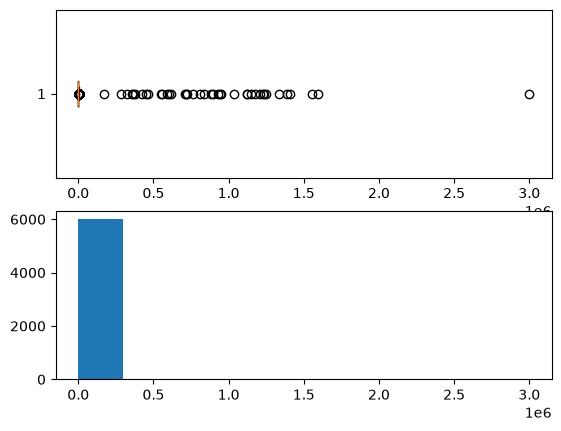

In [47]:
import matplotlib.pyplot as plt
import scipy.stats as mstats



df_copy = df_deliveries.copy()
numerical_columns = [column for column in df_copy.columns if column not in df_copy.select_dtypes(include="str")]
# print(numerical_columns we found that weight kg might be the outlier fille done)
fig, axs = plt.subplots(2,1)


axs[0].boxplot(df_copy['weight_kg'], orientation="horizontal")

axs[1].hist(df_copy['weight_kg'])
# Let's remove outliers
tenth_percentile_weight = df_copy['weight_kg'].quantile(.05)
ninety_percentile_weight = df_copy['weight_kg'].quantile(.95)

print("Kurtosis",df_copy['weight_kg'].kurt())
print("lower %5",tenth_percentile_weight)
print("lower %95",ninety_percentile_weight)


Kurtosis -0.3039972634462704
lower %5 206.982
lower %95 2243.7510000000007


(array([1117.,  940.,  908.,  799.,  613.,  459.,  340.,  238.,  191.,
         430.]),
 array([ 206.94 ,  410.703,  614.466,  818.229, 1021.992, 1225.755,
        1429.518, 1633.281, 1837.044, 2040.807, 2244.57 ]),
 <BarContainer object of 10 artists>)

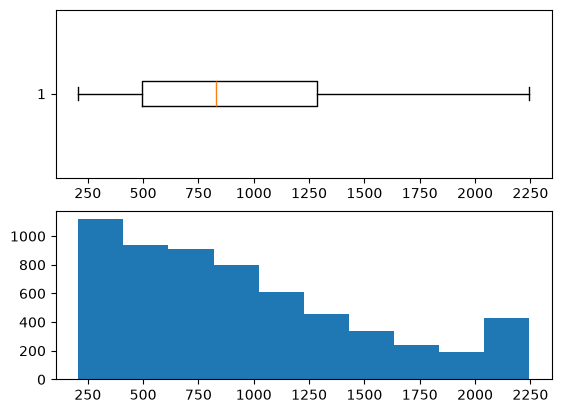

In [48]:
# df_copy['weight_kg'] = mstats.winsorize(df_deliveries['weight_kg'],limits(0.10,0.1))
## there are some impomssible weights like 2,999,300; might be mistake of input and is actually 2,999.30? so clipping to our max
df_copy['weight_kg'] = df_copy['weight_kg'].clip(lower=tenth_percentile_weight,upper=ninety_percentile_weight)

print("Kurtosis", df_copy['weight_kg'].kurt())
print("lower %5",df_copy['weight_kg'].quantile(.05))
print("lower %95",df_copy['weight_kg'].quantile(.95))

fig, axs = plt.subplots(2,1)
axs[0].boxplot(df_copy['weight_kg'], orientation="horizontal")
axs[1].hist(df_copy['weight_kg'])

PReprocessing:
imputation
zindex or iqr for outliers
scaling techniques for outliers (standarization or normalization techniques) MInmax scaler standarscaler. (x-xmin/max-min) / (x-mean/std)
why do we use these techniques?

min-max scaling: (x-xmin)/(xmax-xmin) //not much outliers
standardization: (x-mean)/std difference: min-max scaling brings values to a fixed range [0,1], while standardization centers values around the mean with unit variance. usually used to handle outliers.

skewness -> kurtosis



EDA GOAL:

Discover insights
finding disstributions
finding correlations
finding outliers


Explainabillity: 
use SHAP for model explainability

decision trees: entropy (information gain) for splitting criteria, gini impurity for splitting criteria, and feature importance for explainability.

random forests: feature importance for explainability, uses multiple decision trees to improve accuracy and control overfitting.
gradient boosting: feature importance for explainability, builds trees sequentially to correct errors of previous trees, often achieves high predictive performance.
XGBoost: feature importance for explainability, an optimized gradient boosting library that often achieves state-of-the-art predictive performance.
LightGBM: feature importance for explainability, a gradient boosting framework that uses tree-based learning algorithms, often faster than XGBoost with comparable performance.
CatBoost: feature importance for explainability, a gradient boosting library that handles categorical features automatically, often achieving competitive performance with minimal preprocessing.


Weighted precision: 0.8217696026595621
Weighted recall: 0.7476635514018691
Weighted F1: 0.768371591651973
Confusion matrix [actual rows, predicted columns]:
[[697 238]
 [ 59 183]]
ROC AUC: 0.822


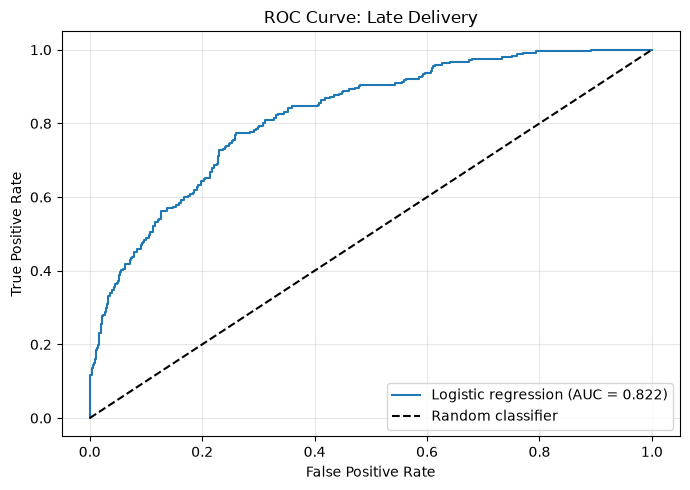

In [49]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support,confusion_matrix, roc_auc_score,roc_curve
from sklearn.preprocessing import StandardScaler

df_deliveries.dropna(subset=['weather_condition'],inplace=True)

y = df_deliveries['delivered_late']
X = df_deliveries.drop(['delivered_late','shipment_id','actual_transit_hours'], axis=1)


#We stratify because we want to retain same proportions
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=.2,stratify=y, random_state=67)

# feat eng?
train_traffic_index_median=X_train['traffic_index'].median()
train_fuel_cost_cad_median=X_train['fuel_cost_cad'].median()
X_train['driver_experience_years']=X_train['driver_experience_years'].fillna(X_train['driver_experience_years'].median())
X_train['traffic_index']=X_train['traffic_index'].fillna(train_traffic_index_median)
X_train['fuel_cost_cad']=X_train['fuel_cost_cad'].fillna(train_fuel_cost_cad_median)

X_test['driver_experience_years']=X_test['driver_experience_years'].fillna(X_test['driver_experience_years'].median())
X_test['traffic_index']=X_test['traffic_index'].fillna(train_traffic_index_median)#X_test['traffic_index'].median())
X_test['fuel_cost_cad']=X_test['fuel_cost_cad'].fillna(train_fuel_cost_cad_median)#X_test['fuel_cost_cad'].median())

categorical_columns = X_train.select_dtypes(include='str').columns
numerical_columns = [column for column in X_train.columns if column not in categorical_columns]

# Winsorization of training data
train_weight_lower_bound = X_train['weight_kg'].quantile(.05)
train_weight_upper_bound = X_train['weight_kg'].quantile(.95)
X_train['weight_kg'] = X_train['weight_kg'].clip(lower=train_weight_lower_bound,upper=train_weight_upper_bound)

# Winsorization of test data
# train_weight_lower_bound = X_test['weight_kg'].quantile(.05)
# train_weight_upper_bound = X_test['weight_kg'].quantile(.95)
X_test['weight_kg'] = X_test['weight_kg'].clip(lower=train_weight_lower_bound,upper=train_weight_upper_bound)

# scaling
scaler = StandardScaler()

X_train[numerical_columns] = scaler.fit_transform(X_train[numerical_columns])
X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])


encoder = OneHotEncoder(sparse_output=False)
# print([list(set(df_deliveries[delivery])) 
#        for delivery 
#        in categorical_columns])
# print(categorical_columns)

encoded_data = encoder.fit_transform(X_train[categorical_columns], y_train)

df_encoded = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(),
    index=X_train.index)

# print(numerical_columns)
X_train = pd.concat([
    X_train[numerical_columns],
    df_encoded
],axis=1)

# print(X_train)

lr = LogisticRegression(class_weight='balanced',max_iter=1000)

model = lr.fit(X_train,y_train)

encoded_data = encoder.transform(X_test[categorical_columns])

df_encoded = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(),
    index=X_test.index
)

X_test = pd.concat([X_test[numerical_columns], df_encoded], 
    axis=1
)




# display(df_encoded)
y_pred = model.predict(X_test)

precision, recall, fscore, support = precision_recall_fscore_support(y_test, y_pred, average="weighted")

print('Weighted precision:', precision)
print('Weighted recall:', recall)
print('Weighted F1:', fscore)
print('Confusion matrix [actual rows, predicted columns]:')
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

y_score = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_score)
roc_auc = roc_auc_score(y_test, y_score)
print(f'ROC AUC: {roc_auc:.3f}')

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'Logistic regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Late Delivery')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Slack warning on new model training result

In [50]:

# import time
import requests
import os
from dotenv import load_dotenv


load_dotenv()

ACCESS_TOKEN = os.getenv("ACCESS_TOKEN")
REFRESH_TOKEN = os.getenv("REFRESH_TOKEN")

# Replace with your actual webhook URL
WEBHOOK_URL = os.getenv("WEBHOOK_URL")


def send_slack_message(message):
    payload = {"text": message}
    requests.post(WEBHOOK_URL, json=payload)


# Example: Simulate training alerts
# for epoch in range(1, 6):
#     accuracy = 0.7 + epoch * 0.05
epoch = 3000
msg = f"Training Update for Maple Freight - Epoch {epoch}: Precision = {precision:.2f} ROC AUC = {roc_auc:.2f}"
send_slack_message(msg)
# time.sleep(2)  # simulate processing time

send_slack_message("✅ Training Completed!")

